# A neural network from scratch, derived and verified

I wrote this library to answer one question properly: can I build everything a
deep learning framework hides, prove the gradients are correct, and train real
classifiers with it, using nothing but NumPy?

This notebook is the walkthrough. It follows the order I actually worked in:

1. Write down the forward pass.
2. Derive backpropagation with the chain rule, layer by layer.
3. Prove the implementation correct with a numerical gradient check.
4. Derive the optimizer update rules and race them against each other.
5. Watch the network carve a nonlinear decision boundary on the two moons set.
6. Scale the same code up to handwritten digits.

Everything runs offline. The two moons data is committed at
`data/two_moons.csv` and was generated by `scripts/make_toy_data.py` with a
fixed seed. The full derivations also live in `docs/math.md`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np

from nnscratch import (
    Adam,
    Dense,
    Momentum,
    ReLU,
    SGD,
    Sequential,
    SoftmaxCrossEntropy,
    accuracy,
    gradient_check,
    load_two_moons,
    train,
)

SURFACE, GRID, INK = "#fcfcfb", "#e1e0d9", "#898781"
CLASS_COLORS = ("#2a78d6", "#e34948")
plt.rcParams["figure.facecolor"] = SURFACE
plt.rcParams["axes.facecolor"] = SURFACE

## 1. The forward pass

A feedforward classifier is a chain of small functions. For a batch $X$ with
one sample per row, each `Dense` layer computes an affine map, and each
activation bends it:

$$Z = XW + b, \qquad A = \mathrm{ReLU}(Z) = \max(0, Z)$$

Stack a few of those and finish with a `Dense` layer that outputs one score
(logit) per class. The softmax turns logits $z$ into probabilities and cross
entropy scores them against the true class $y$:

$$p_j = \frac{e^{z_j}}{\sum_k e^{z_k}}, \qquad L = -\log p_y$$

That is the whole forward story. Let me load the committed two moons set, the
dataset the network will have to bend around: two interleaving half circles
plus Gaussian noise, so no straight line can separate them.

train (300, 2), test (100, 2)


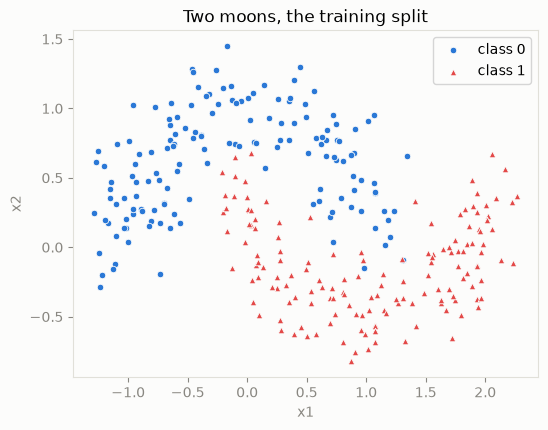

In [2]:
x_train, x_test, y_train, y_test = load_two_moons(path="../data/two_moons.csv", seed=0)
print(f"train {x_train.shape}, test {x_test.shape}")

fig, ax = plt.subplots(figsize=(6, 4.5))
for cls, color, marker in ((0, CLASS_COLORS[0], "o"), (1, CLASS_COLORS[1], "^")):
    mask = y_train == cls
    ax.scatter(x_train[mask, 0], x_train[mask, 1], s=22, c=color, marker=marker,
               edgecolors=SURFACE, linewidths=0.6, label=f"class {cls}")
ax.set_xlabel("x1", color=INK)
ax.set_ylabel("x2", color=INK)
ax.tick_params(colors=INK)
for spine in ax.spines.values():
    spine.set_color(GRID)
ax.set_title("Two moons, the training split")
ax.legend()
plt.show()

## 2. Deriving backpropagation

Backpropagation is not a separate algorithm, it is the chain rule with good
bookkeeping. For any tensor $T$ in the network I write $dT$ for
$\partial L / \partial T$, which always has the same shape as $T$. Every layer
implements one contract: given $dZ$ for its output, return $dX$ for its input
and store the gradients of its own parameters. The `Sequential` container
calls `backward` in reverse layer order and no layer needs to know its
neighbors.

**Softmax plus cross entropy, fused.** Writing the loss for one sample as
$L = -z_y + \log \sum_k e^{z_k}$ and differentiating with respect to $z_j$:

$$\frac{\partial L}{\partial z_j} = p_j - \mathbb{1}[j = y]$$

This is why the library fuses the two operations: the fused gradient is one
subtraction, while softmax alone would need a $C \times C$ Jacobian per
sample.

**The Dense layer.** With $Z = XW + b$ and $dZ$ arriving from above, the
chain rule gives three gradients, and the array shapes force each formula,
there is only one way to multiply the arrays into the right shape:

$$dW = X^\top dZ, \qquad db = \textstyle\sum_i dZ_i, \qquad dX = dZ\, W^\top$$

**Activations.** Elementwise functions have diagonal Jacobians, so backward
is an elementwise product with the local derivative:

$$\mathrm{ReLU}: \; dZ = dA \odot \mathbb{1}[Z > 0], \qquad
\sigma: \; dZ = dA \odot \sigma(Z)(1 - \sigma(Z))$$

Each of these is two or three lines in `src/nnscratch/layers.py`. The full
index-level derivation is in `docs/math.md`.

## 3. The correctness proof: gradient checking

A derivation on paper is not evidence that the code is right. The proof is
numerical: for every parameter entry $p_i$, the central difference

$$\frac{\partial L}{\partial p_i} \approx \frac{L(p_i + \varepsilon) - L(p_i - \varepsilon)}{2\varepsilon}$$

approximates the gradient with error $O(\varepsilon^2)$ and knows nothing
about my backward pass. I compare it against backpropagation with the
symmetric relative error. A correct implementation lands near $10^{-8}$ in
float64. A wrong one lands near $10^{-2}$ or worse. There is no ambiguity.

One practical detail: I take a few warmup training steps before checking.
With zero-initialized biases, a sample whose entire hidden layer is dead puts
the next preactivation exactly on the ReLU kink, where a central difference
straddles the non-differentiable point. Checking at a generic, trained point
avoids that measure-zero coincidence. The test suite in
`tests/test_gradient_check.py` runs this check per layer and for whole
networks with ReLU, Sigmoid, depth, and L2 regularization active.

In [3]:
def build_model(hidden: int, seed: int = 0) -> Sequential:
    rng = np.random.default_rng(seed)
    return Sequential([
        Dense(2, hidden, init="he", rng=rng),
        ReLU(),
        Dense(hidden, hidden, init="he", rng=rng),
        ReLU(),
        Dense(hidden, 2, init="xavier", rng=rng),
    ])

check_model = build_model(hidden=8)
check_x, check_y = x_train[:16], y_train[:16]
train(check_model, Adam(lr=0.01), check_x, check_y,
      epochs=3, batch_size=16, rng=np.random.default_rng(0))

rel_error = gradient_check(check_model, SoftmaxCrossEntropy(), check_x, check_y)
print(f"max symmetric relative error over all parameter arrays: {rel_error:.2e}")
assert rel_error < 1e-7, "backpropagation disagrees with numerical gradients"
print("backpropagation verified against central differences")

max symmetric relative error over all parameter arrays: 5.06e-09
backpropagation verified against central differences


## 4. The optimizer update rules

After backward, every parameter $p$ holds a gradient $g$. The three
optimizers differ only in how they turn $g$ into a step.

**SGD** takes the gradient at face value:

$$p \leftarrow p - \eta\, g$$

**Momentum** accumulates a velocity, damping oscillations across steep
directions and accelerating along consistent ones:

$$v \leftarrow \mu v - \eta g, \qquad p \leftarrow p + v$$

**Adam** keeps per-parameter moment estimates with bias correction, so the
step size adapts to the gradient scale:

$$m \leftarrow \beta_1 m + (1-\beta_1) g, \quad
v \leftarrow \beta_2 v + (1-\beta_2) g^2, \quad
p \leftarrow p - \eta\, \frac{\hat m}{\sqrt{\hat v} + \epsilon}$$

where $\hat m = m / (1 - \beta_1^t)$ and $\hat v = v / (1 - \beta_2^t)$. The
bias correction is why Adam's very first step already has magnitude close to
$\eta$, a property the test suite checks directly.

Let me race the three from identical initial weights on two moons.

sgd (lr=0.1)         final training loss 0.0632  test accuracy 0.970


momentum (lr=0.05)   final training loss 0.0462  test accuracy 0.980


adam (lr=0.01)       final training loss 0.0372  test accuracy 0.970


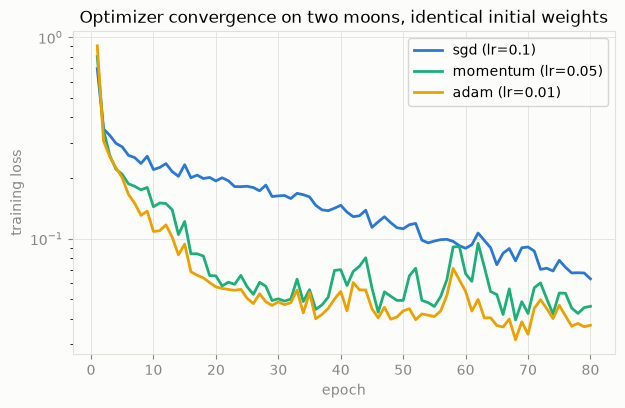

In [4]:
optimizers = {
    "sgd (lr=0.1)": SGD(lr=0.1),
    "momentum (lr=0.05)": Momentum(lr=0.05),
    "adam (lr=0.01)": Adam(lr=0.01),
}
series_colors = ("#2a78d6", "#1baf7a", "#eda100")

histories = {}
for name, opt in optimizers.items():
    model = build_model(hidden=32, seed=0)  # same seed, identical start
    histories[name] = train(model, opt, x_train, y_train,
                            epochs=80, batch_size=32,
                            rng=np.random.default_rng(0))
    print(f"{name:20s} final training loss {histories[name].loss[-1]:.4f}  "
          f"test accuracy {accuracy(model, x_test, y_test):.3f}")

fig, ax = plt.subplots(figsize=(7, 4.2))
for (name, history), color in zip(histories.items(), series_colors):
    ax.plot(range(1, 81), history.loss, label=name, color=color, linewidth=2)
ax.set_yscale("log")
ax.set_xlabel("epoch", color=INK)
ax.set_ylabel("training loss", color=INK)
ax.tick_params(colors=INK)
ax.grid(True, color=GRID, linewidth=0.6)
for spine in ax.spines.values():
    spine.set_color(GRID)
ax.set_title("Optimizer convergence on two moons, identical initial weights")
ax.legend()
plt.show()

## 5. The decision boundary

Time to see what all this machinery buys. I train the 2-32-32-2 network with
Adam and paint the plane with its predicted probability of class 1. The
diverging colors show the model's confidence field, and the black contour at
$p = 0.5$ is the decision boundary. Two hidden ReLU layers are plenty to bend
the boundary around both moons.

In [5]:
model = build_model(hidden=32, seed=0)
history = train(model, Adam(lr=0.01), x_train, y_train,
                x_val=x_test, y_val=y_test,
                epochs=200, batch_size=32, rng=np.random.default_rng(0))
train_acc = accuracy(model, x_train, y_train)
test_acc = accuracy(model, x_test, y_test)
print(f"train accuracy {train_acc:.3f}, test accuracy {test_acc:.3f}")

train accuracy 0.990, test accuracy 0.960


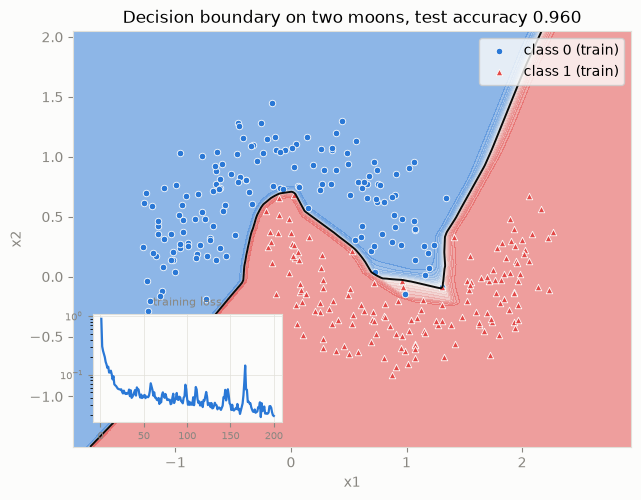

In [6]:
from matplotlib.colors import LinearSegmentedColormap

prob_cmap = LinearSegmentedColormap.from_list(
    "moons_diverging", ["#2a78d6", "#f0efec", "#e34948"])

all_x = np.vstack([x_train, x_test])
margin, steps = 0.6, 300
xx, yy = np.meshgrid(
    np.linspace(all_x[:, 0].min() - margin, all_x[:, 0].max() + margin, steps),
    np.linspace(all_x[:, 1].min() - margin, all_x[:, 1].max() + margin, steps),
)
logits = model.forward(np.column_stack([xx.ravel(), yy.ravel()]))
shifted = np.exp(logits - logits.max(axis=1, keepdims=True))
probs = (shifted[:, 1] / shifted.sum(axis=1)).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(7.2, 5.4))
ax.contourf(xx, yy, probs, levels=np.linspace(0, 1, 21), cmap=prob_cmap, alpha=0.55)
ax.contour(xx, yy, probs, levels=[0.5], colors="#0b0b0b", linewidths=1.4)
for cls, color, marker in ((0, CLASS_COLORS[0], "o"), (1, CLASS_COLORS[1], "^")):
    mask = y_train == cls
    ax.scatter(x_train[mask, 0], x_train[mask, 1], s=22, c=color, marker=marker,
               edgecolors=SURFACE, linewidths=0.6, label=f"class {cls} (train)")
ax.set_xlabel("x1", color=INK)
ax.set_ylabel("x2", color=INK)
ax.tick_params(colors=INK)
for spine in ax.spines.values():
    spine.set_color(GRID)
ax.set_title(f"Decision boundary on two moons, test accuracy {test_acc:.3f}")
ax.legend(loc="upper right")

inset = ax.inset_axes([0.035, 0.06, 0.34, 0.26])
inset.plot(range(1, len(history.loss) + 1), history.loss, color="#2a78d6", linewidth=1.6)
inset.set_yscale("log")
inset.set_title("training loss", fontsize=8, color=INK)
inset.tick_params(labelsize=7, colors=INK)
inset.grid(True, color=GRID, linewidth=0.5)
for spine in inset.spines.values():
    spine.set_color(GRID)
plt.show()

The same picture, regenerated by `scripts/plot_decision_boundary.py`, is the
repository's hero figure at `results/decision_boundary.png`, together with
`results/metrics.json` and the trained weights `results/two_moons_model.npz`.

## 6. Scaling up: handwritten digits

Nothing in the library is specific to two dimensions. The same layers, loss,
and training loop handle the 8x8 digits set bundled with scikit-learn (64
input features, 10 classes), still offline.

In [7]:
from nnscratch import Dropout
from nnscratch.data import load_digits_data

dx_train, dx_test, dy_train, dy_test = load_digits_data(seed=0)
rng = np.random.default_rng(0)
digits_model = Sequential([
    Dense(64, 128, init="he", l2=1e-4, rng=rng),
    ReLU(),
    Dropout(0.1, rng=rng),
    Dense(128, 128, init="he", l2=1e-4, rng=rng),
    ReLU(),
    Dense(128, 10, init="xavier", rng=rng),
])
digits_history = train(digits_model, Adam(lr=0.001), dx_train, dy_train,
                       x_val=dx_test, y_val=dy_test,
                       epochs=20, batch_size=64, rng=np.random.default_rng(0))
digits_acc = accuracy(digits_model, dx_test, dy_test)
print(f"digits test accuracy after 20 epochs: {digits_acc:.4f}")

digits test accuracy after 20 epochs: 0.9778


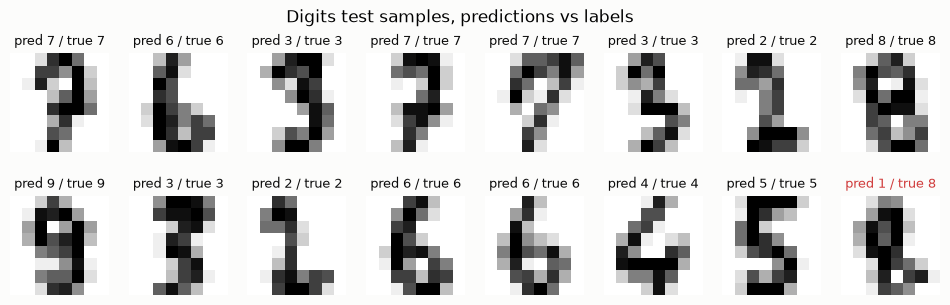

In [8]:
preds = digits_model.predict(dx_test)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for i, ax in enumerate(axes.flat):
    ax.imshow(dx_test[i].reshape(8, 8), cmap="gray_r")
    correct = preds[i] == dy_test[i]
    ax.set_title(f"pred {preds[i]} / true {dy_test[i]}",
                 fontsize=9, color="#0b0b0b" if correct else "#d03b3b")
    ax.axis("off")
fig.suptitle("Digits test samples, predictions vs labels")
plt.show()

## Where to go from here

- `docs/math.md` carries the full index-level derivations that this notebook
  compresses.
- `tests/test_gradient_check.py` is the part of the test suite I trust most:
  per-layer and whole-network numerical checks that would catch any wrong
  gradient immediately.
- `scripts/train.py` trains on two moons, digits, or full MNIST from the
  command line, and `scripts/benchmark.py` reproduces the optimizer
  comparison figure.
- The natural next steps, none of which are implemented here on purpose, are
  batch normalization, convolutions, and a real autograd graph. This library
  is the baseline that makes those understandable.